<a href="https://colab.research.google.com/github/achyutdipu/XKAD/blob/main/XKAD_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINNs with XKAD

In [1]:
!pip install deepxde
# If you are using Google Colab, you can uncomment the line above to install the DeepXDE library. Also, change runtime type to GPU for better performance.
# Use backend tensorflow.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [deepxde]


In [2]:
#Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import deepxde as dde
import seaborn as sns
import tensorflow as tf

from scipy.integrate import solve_ivp

No backend selected.
Finding available backend...
Found tensorflow
Using backend: tensorflow
Other supported backends: tensorflow.compat.v1, pytorch, jax, paddle.
paddle supports more examples now and is recommended.


Setting the default backend to "tensorflow". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


In [8]:
# Initial metadata.
X_0 = 10
K_0 = 1
A_0 = 26
D_0 = 5.7
y0 = [X_0, D_0, A_0, D_0]
df = pd.read_csv("electricity_prices.csv", parse_dates=["Date"])
E = df['Cents/kWh'].to_numpy()[-97:].copy()
beta_one, r_one, lambda_, mu, eta, r_two, beta_two, theta, k, delta, rho, sigma, z, omega = 0.033, 3.8e-1, 0.0058, 0.00028, 0.0094, 3.5e-1, 0.012, 0.00032, 1, 0.04, 0.01, 0.0001, 0.003, 0.02
parameters_real = {
  "beta_one": beta_one,
  "r_one": r_one,
  "lambda": lambda_,
  "mu": mu,
  "beta_two": beta_two,
  "r_two": r_two,
  "eta": eta,
  "theta": theta,
  "k": k,
  "delta": delta,
  "rho": rho,
  "sigma": sigma,
  "z": z,
  "omega": omega
}
n_months = 96
noise = 0.025
neurons = 64
layers = 3
activation = "tanh"
num_iterations = 20_000

[[  6.8394662    6.55417063  28.99481916   5.74581386]
 [ 10.10800043   5.92259818  23.14385741   5.6621417 ]
 [ 12.64905872  10.18631354  25.70245939   5.82341337]
 [ 17.59334632  12.22909282  29.28331304   5.65136949]
 [ 16.23107821  12.72715422  30.58731652   5.74297533]
 [ 22.56548039  16.36517365  30.03241469   5.75189447]
 [ 26.50264778  17.0131271   31.67945137   5.61680712]
 [ 27.07825412  17.6970038   32.55232121   5.7054762 ]
 [ 29.71484479  20.65010523  33.54298727   5.83072322]
 [ 35.15526701  24.85355261  33.18268421   5.86735108]
 [ 34.29668402  23.59642277  34.79421281   5.7037859 ]
 [ 39.44164647  27.11991159  37.39471265   5.80833872]
 [ 39.38263285  28.85113843  38.39725402   5.51228992]
 [ 43.29747272  29.96342237  37.26646675   5.60379248]
 [ 41.5112337   32.92230041  39.88371332   5.74084524]
 [ 46.78330428  33.65894527  41.56952686   5.70130359]
 [ 48.12486639  35.01556981  40.88174767   5.79639358]
 [ 50.70563524  37.55410147  43.48984393   5.80274698]
 [ 56.6032

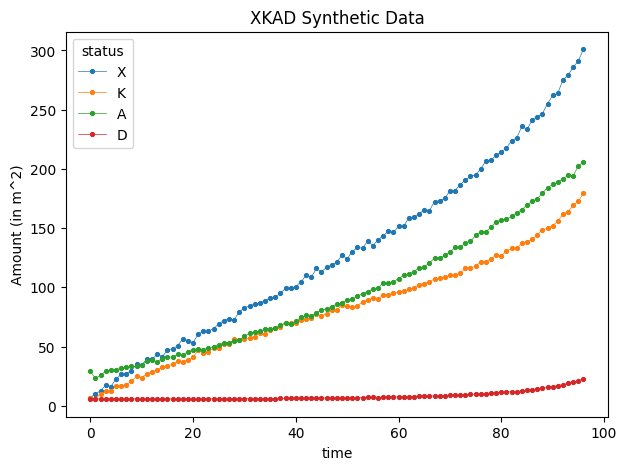

In [10]:
# Generating synthetic data
def generate_data(t_array, y0, args=(beta_one, r_one, lambda_, mu, eta, r_two, beta_two, theta, k, delta, rho, sigma, z, omega)):
  args = beta_one, r_one, lambda_, mu, eta, r_two, beta_two, theta, k, delta, rho, sigma, z, omega
  def func(t, y):
    X, K, A, D = y
    E_t = np.interp(t, t_array, E)
    dX_dt = beta_one*E_t + r_one*D - lambda_*K - mu*X
    dK_dt = beta_two*E_t + r_two*D - eta*X - theta*K
    dA_dt = k + delta*(X-K) - rho*A - sigma*A*D
    dD_dt = sigma*A*D + z*D*D - omega*D
    return [dX_dt, dK_dt, dA_dt, dD_dt]
  t_span = (t_array[0], t_array[-1])
  sol = solve_ivp(func, t_span, y0, t_eval=t_array)
  return sol.y.T

t_train = np.arange(0, n_months + 1)[:, np.newaxis]
y_train = generate_data(np.ravel(t_train), y0)
y_train += np.random.normal(loc=0, scale=y_train.std(axis=0), size=y_train.shape) * noise
print(y_train)
print(y_train.shape)
print(t_train.shape, E.shape)
data_input_train = np.hstack((t_train, E[:, np.newaxis]))
names = list("XKAD")
data_real = (
  pd.DataFrame(y_train, columns=names, index=t_train.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in m^2)")
)
print(data_real)
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(
  x="time",
  y="Amount (in m^2)",
  hue="status",
  marker='o',
  linewidth=.5,
  markersize=3,
  markeredgecolor=None,
  data=data_real,
  ax=ax
)
ax.set(title="XKAD Synthetic Data")
fig.savefig("XKAD Synthetic Data.jpg")

In [12]:
# Custom class to run transformation function T(x) on dde.Variables.
class TransformedVariable(dde.callbacks.Callback):
  def __init__(self, var_list, period=1, filename=None, precision=2, transforms=None):
    super().__init__()
    self.var_list = var_list if isinstance(var_list, list) else [var_list]
    self.period = period
    self.file = open(filename, "w") if filename else None
    self.precision = precision
    self.transforms = transforms
    assert len(var_list) == len(var_list) if transforms else True
  def on_train_begin(self):
    header = "Step      Train loss                        Test loss                         Test metric"
    if self.file is None:
      print(header)
  def on_epoch_end(self):
    if self.transforms is None:
      return super().on_epoch_end()
    step = self.model.train_state.step
    if step % self.period == 0:
      t_vals = [self.transforms[idx](var) for idx, var in enumerate(self.var_list)]
      train_loss = self.model.train_state.loss_train
      test_loss = self.model.train_state.loss_test
      metrics = self.model.train_state.metrics_test
      from deepxde.utils import list_to_str
      str_vars = list_to_str(t_vals, precision=self.precision)
      str_train = list_to_str(train_loss, precision=self.precision)
      str_test = list_to_str(test_loss, precision=self.precision)
      str_metrics = list_to_str(metrics, precision=self.precision)
      output_line = f"{step:<9} {str_train:<33} {str_test:<33} {str_metrics}"
      if self.file:
        self.file.write(str(step) + " " + list_to_str([self.transforms[idx](var).numpy() for idx, var in enumerate(self.model.external_trainable_variables)]) + "\n")
        self.file.flush()
      else:
        print(output_line)
  def on_train_end(self):
    if self.transforms is not None:
      self.value = [self.transforms[idx](var).numpy() for idx, var in enumerate(self.var_list)]
    else:
      self.value = [var.numpy() for var in self.var_list]
    if self.file:
      self.file.close()

Compiling model...
'compile' took 0.013951 s

Training model...

Step      Train loss                                                                          Test loss                                                                           Test metric
0         [3.93e-04, 2.98e-04, 1.52e-03, 9.11e-04, 2.30e+04, 8.71e+03, 1.15e+04, 7.33e+01]    [3.98e-04, 2.98e-04, 1.51e-03, 9.21e-04, 2.30e+04, 8.71e+03, 1.15e+04, 7.33e+01]    []  
400       [2.68e-01, 2.17e-01, 1.31e-01, 2.04e-02, 1.56e+04, 4.96e+03, 6.96e+03, 1.40e+01]    [2.73e-01, 2.21e-01, 1.32e-01, 2.05e-02, 1.56e+04, 4.96e+03, 6.96e+03, 1.40e+01]    []  
800       [1.33e-01, 1.31e-01, 1.77e-02, 2.74e-02, 1.16e+04, 2.98e+03, 4.58e+03, 1.32e+01]    [1.34e-01, 1.31e-01, 1.78e-02, 2.76e-02, 1.16e+04, 2.98e+03, 4.58e+03, 1.32e+01]    []  
1200      [1.58e-01, 2.08e-01, 1.01e-01, 1.13e-02, 8.57e+03, 1.82e+03, 3.08e+03, 1.24e+01]    [1.57e-01, 2.06e-01, 9.90e-02, 1.14e-02, 8.57e+03, 1.82e+03, 3.08e+03, 1.24e+01]    []  
1600      [2.

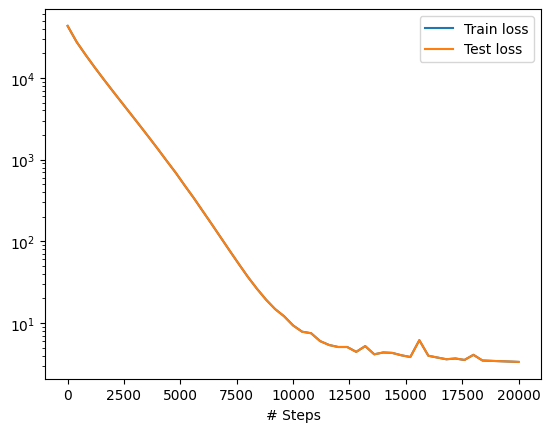

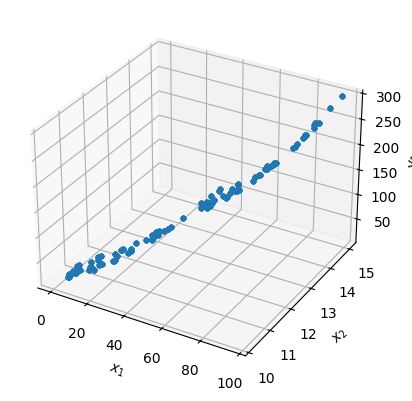

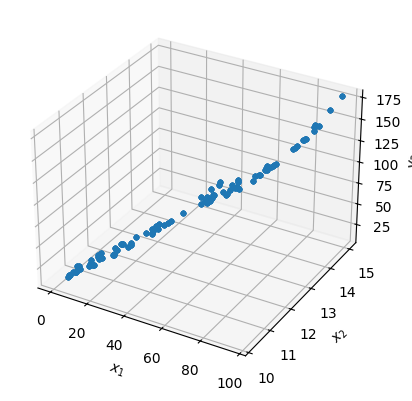

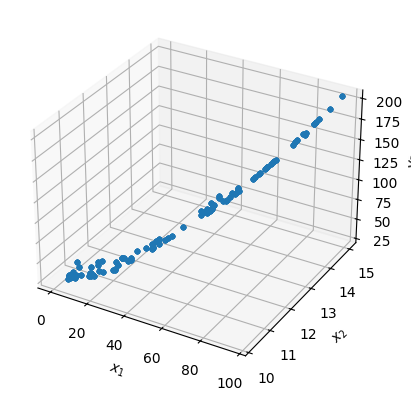

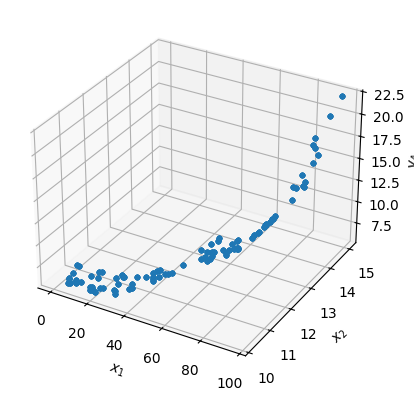

In [13]:
# PINNs
geom = dde.geometry.PointCloud(data_input_train)

_beta_one = dde.Variable(0.01)
_r_one = dde.Variable(0.01)
_r_two = dde.Variable(0.01)
_lambda = dde.Variable(0.01)
_mu = dde.Variable(0.01)
_eta = dde.Variable(0.01)
_beta_two = dde.Variable(0.01)
_theta = dde.Variable(0.01)
_k = dde.Variable(0.01)
_delta = dde.Variable(0.01)
_rho = dde.Variable(0.01)
_sigma = dde.Variable(0.01)
_z = dde.Variable(0.01)
_omega = dde.Variable(0.01)
def helper(var):
  return tf.math.sqrt(tf.math.abs(var*tf.math.square(tf.math.tanh(var))))
def ode(t, y):
  E = t[:, 1:2]
  X = y[:, 0:1]
  K = y[:, 1:2]
  A = y[:, 2:3]
  D = y[:, 3:4]
  dX_dt = dde.grad.jacobian(y, t, i=0, j=0)
  dK_dt = dde.grad.jacobian(y, t, i=1, j=0)
  dA_dt = dde.grad.jacobian(y, t, i=2, j=0)
  dD_dt = dde.grad.jacobian(y, t, i=3, j=0)
  beta_one_t = helper(_beta_one)
  r_one_t = helper(_r_one)
  lambda_t = helper(_lambda)
  mu_t = helper(_mu)
  eta_t = helper(_eta)
  beta_two_t = helper(_beta_two)
  r_two_t = helper(_r_two)
  theta_t = helper(_theta)
  k_t = helper(_k)
  delta_t = helper(_delta)
  rho_t = helper(_rho)
  sigma_t = helper(_sigma)
  z_t = helper(_z)
  omega_t = helper(_omega)
  return [
      dX_dt - (beta_one_t * E + r_one_t * D - lambda_t * K - mu_t * X),
      dK_dt - (beta_two_t * E + r_two_t * D - eta_t * X - theta_t * K),
      dA_dt - (k_t + delta_t * (X - K) - rho_t * A - sigma_t * A * D),
      dD_dt - (sigma_t * A * D + z_t * D * D - omega_t * D * D),
    ]
observed_X = dde.icbc.PointSetBC(data_input_train, y_train[:, 0:1], component=0)
observed_K = dde.icbc.PointSetBC(data_input_train, y_train[:, 1:2], component=1)
observed_A = dde.icbc.PointSetBC(data_input_train, y_train[:, 2:3], component=2)
observed_D = dde.icbc.PointSetBC(data_input_train, y_train[:, 3:4], component=3)

data = dde.data.PDE(
  geom,
  ode,
  [observed_X, observed_K, observed_A, observed_D],
  num_domain=0,
  num_boundary=0,
  num_test=512,
  anchors=data_input_train,
)
net = dde.nn.FNN([1] + [neurons] * layers + [4], activation, "Glorot normal")
model = dde.Model(data, net)
model.compile(
  "adam",
  lr=1e-3,
  external_trainable_variables=[_beta_one, _r_one, _lambda, _mu, _eta, _r_two, _beta_two, _theta, _k, _delta, _rho, _sigma, _z, _omega]
)
variable_filename = f"data_{num_iterations}_steps"
variable = TransformedVariable(
  [_beta_one, _r_one, _lambda, _mu, _eta, _r_two, _beta_two, _theta, _k, _delta, _rho, _sigma, _z, _omega],
  period=100,
  filename=variable_filename,
  transforms=[
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper
  ]
)
losshistory, train_state = model.train(
  iterations=num_iterations,
  display_every=num_iterations // 50,
  callbacks=[variable]
)
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [14]:
# Errors
parameter_names = list(parameters_real.keys())
print(variable.value)
errors = (
  pd.DataFrame(
    {"real": parameters_real, "predicted": variable.value},
    index=parameter_names
  )
  .assign(
    relative_error=lambda x: (x["real"] - x["predicted"]).abs() / x["real"]
  )
)
errors

[np.float32(0.08553508), np.float32(0.22945969), np.float32(1.7829027e-10), np.float32(2.881595e-10), np.float32(0.0060275653), np.float32(0.23487328), np.float32(0.045063473), np.float32(3.312231e-13), np.float32(0.8245941), np.float32(0.028526459), np.float32(2.0735848e-14), np.float32(0.00036237846), np.float32(0.02618468), np.float32(0.027927117)]


,real,predicted,relative_error
beta_one,0.03300,8.553508e-02,1.591972
r_one,0.38000,2.294597e-01,0.396159
lambda,0.00580,1.782903e-10,1.000000
mu,0.00028,2.881595e-10,0.999999
beta_two,0.01200,6.027565e-03,0.497703
r_two,0.35000,2.348733e-01,0.328933
eta,0.00940,4.506347e-02,3.793987
theta,0.00032,3.312231e-13,1.000000
k,1.00000,8.245941e-01,0.175406
delta,0.04000,2.852646e-02,0.286839


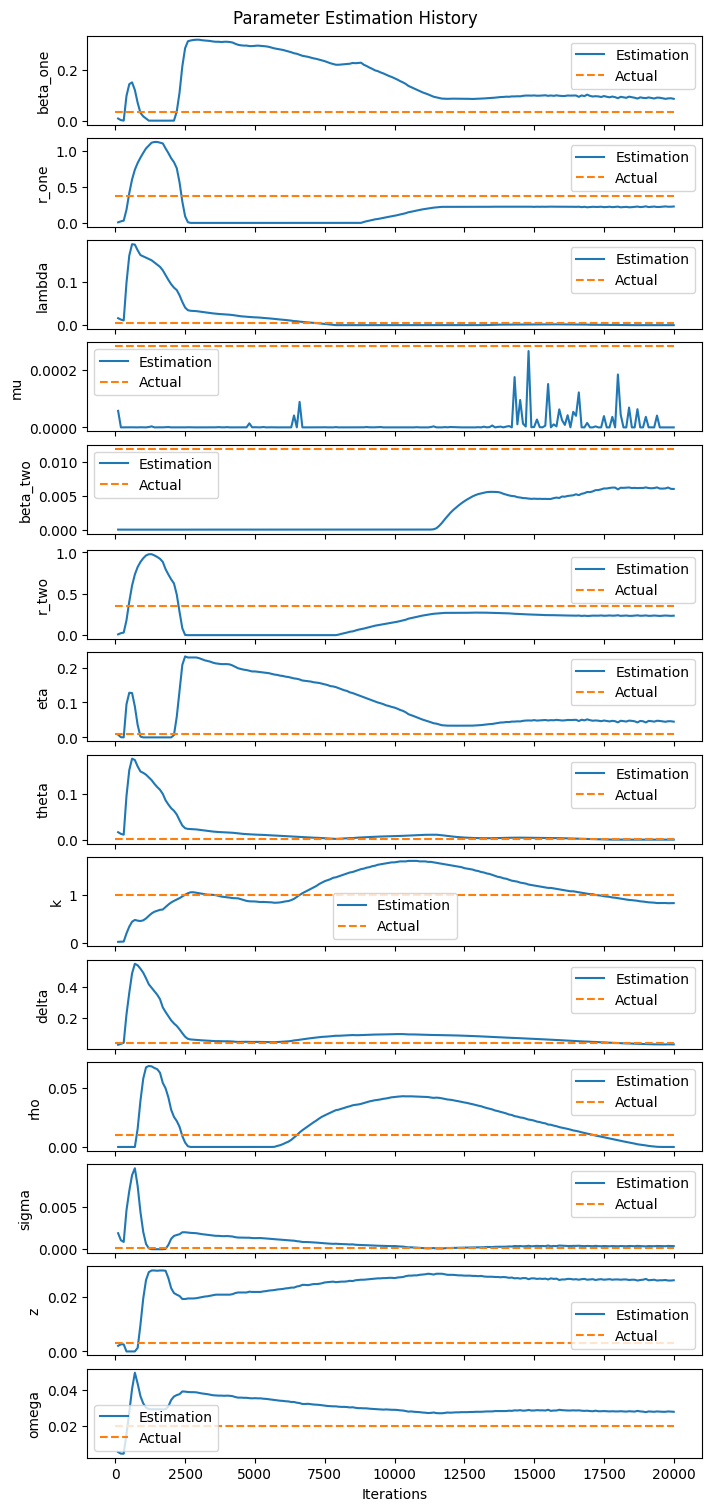

In [15]:
# Learning History
lines = open(variable_filename, "r").readlines()
raw_parameters_pred_history = np.array(
  [
    np.fromstring(
      min(re.findall(re.escape("[") + "(.*?)" + re.escape("]"), line), key=len),
      sep=",",
    ) for line in lines
  ]
)
iterations = [int(re.findall("^[0-9]+", line)[0]) for line in lines]
parameters_pred_history = {
  name: raw_parameters_pred_history[:, i]
  for i, name in enumerate(parameters_real.keys())
}

n_callbacks, n_variables = raw_parameters_pred_history.shape
fig, axes = plt.subplots(nrows=n_variables, sharex=True, figsize=(7, 15), layout="constrained")
for ax, (parameter, parameter_value) in zip(axes, parameters_real.items()):
  ax.plot(iterations, parameters_pred_history[parameter] , "-", label="Estimation")
  ax.hlines(parameter_value, xmin=0, xmax=num_iterations, linestyles="dashed",  color=sns.color_palette()[1], label="Actual")
  ax.set_ylabel(parameter)
  ax.legend()
ax.set_xlabel("Iterations")
fig.suptitle("Parameter Estimation History")
fig.savefig("XKAD Parameter Estimation History.jpg", dpi=300, bbox_inches="tight")
fig.show()

97
(97,)
(97,)
     time         status  Amount (in specified units)
0       0  X (Predicted)                    10.000000
1       1  X (Predicted)                    12.486505
2       2  X (Predicted)                    14.955036
3       3  X (Predicted)                    17.401387
4       4  X (Predicted)                    19.828888
..    ...            ...                          ...
383    92  D (Predicted)                    17.854474
384    93  D (Predicted)                    18.851457
385    94  D (Predicted)                    19.972763
386    95  D (Predicted)                    21.243544
387    96  D (Predicted)                    22.695291

[388 rows x 3 columns]
     time         status  Amount (in specified units)
0       0              X                     9.417313
1       1              X                    13.869412
2       2              X                    17.397912
3       3              X                    20.331437
4       4              X                   

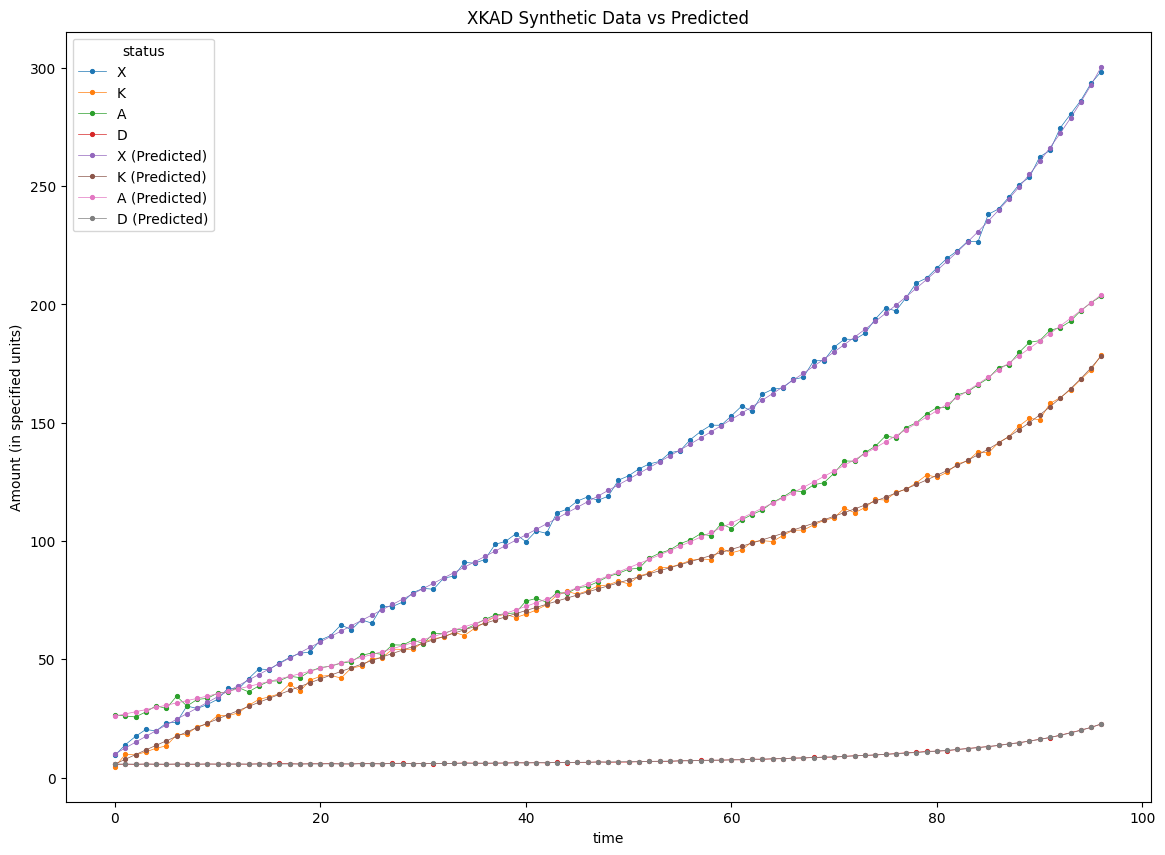

In [16]:
pred_values = [v[-1] for v in parameters_pred_history.values()]
pred_names = [i+" (Predicted)" for i in names]
t_train = np.arange(0, 97)
y_pred = generate_data(np.ravel(t_train), y0, args=tuple(pred_values))
y_train = generate_data(np.ravel(t_train), y0) + np.random.normal(loc=0, scale=y_train.std(axis=0), size=y_pred.shape) * noise
print(y_pred.shape[0])
print(t_train.shape)
t_pred = t_train[:y_pred.shape[0]]
print(t_pred.shape)
data_pred = (
  pd.DataFrame(y_pred, columns=pred_names, index=t_pred.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in specified units)")
)
data_real = (
  pd.DataFrame(y_train, columns=names, index=t_train.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in specified units)")
)
print(data_pred)
data_total = pd.concat([data_real, data_pred], ignore_index=True)
print(data_total)
residuals = y_train-y_pred
ssres = np.pow(residuals, 2).sum()
mse = ssres/len(residuals)
rmse = np.sqrt(mse)
sstot = np.pow(np.abs(y_train-y_train.mean()), 2).sum()
r2 = 1-ssres/sstot
mape = (np.abs(residuals)/y_train).sum()*100/len(residuals)
print(mse, rmse, r2, mape)
no_noise = generate_data(np.ravel(t_train), y0)
residuals_nonoise = no_noise-y_pred
ssres_nonoise = np.pow(residuals_nonoise, 2).sum()
mse_nonoise = ssres_nonoise/len(residuals_nonoise)
rmse_nonoise = np.sqrt(mse_nonoise)
sstot_nonoise = np.pow(np.abs(no_noise-no_noise.mean()), 2).sum()
r2_nonoise = 1-ssres_nonoise/sstot_nonoise
mape_nonoise = (np.abs(residuals_nonoise)/no_noise).sum()*100/len(residuals_nonoise)
print(mse_nonoise, rmse_nonoise, r2_nonoise, mape_nonoise)
normrmse = rmse/np.sum(np.square(y_train))
normrmse_nonoise = rmse_nonoise/np.sum(np.square(no_noise))
print(normrmse)
print(normrmse_nonoise)
fig, ax = plt.subplots(figsize=(14, 10))
sns.lineplot(
  x="time",
  y="Amount (in specified units)",
  hue="status",
  marker='o',
  linewidth=.5,
  markersize=3,
  markeredgecolor=None,
  data=data_total,
  ax=ax
)
ax.set(title="XKAD Synthetic Data vs Predicted")
fig.savefig("XKAD Synthetic Data vs Predicted.jpg", dpi=300, bbox_inches="tight")
fig.show()

#Sensitivity Analysis

In [11]:
!pip install SALib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.1/800.1 kB 11.3 MB/s  0:00:00


In [ ]:
from SALib.sample import saltelli
from SALib.analyze import sobol
import scipy
from tqdm import tqdm
from sympy.parsing.latex import parse_latex
from sympy import pretty, init_printing
init_printing(use_latex=False, use_unicode=True)
def get_list_shape(x):
    if not isinstance(x, list):
        return ()
    return (len(x),) + get_list_shape(x[0])
INTERVAL = [0, 120]
POINTS_ALONG_INTERVAL = 101
I = 1
alpha = 0.02
beta_one = 0.033
r_one = 3.8e-1
r_two = 3.8e-1
lambda_ = 0.0058
mu = 0.028
eta = 0.0094
beta_two = 0.012
theta = 0.032
k = 1
delta = 0.012
rho = 0.01
sigma = 0.0001
z = 0.003
omega = 0.02
TRUE_PARAMETERS = (I, alpha, beta_one, r_one, r_two, lambda_, mu, eta, beta_two, theta, k, delta, rho, sigma, z, omega)
PARAMETER_SYMBOLS = [
    r"$I$",
    r"$\alpha$",
    r"$\beta_1$",
    r"$r_1$",
    r"$r_2$",
    r"$\lambda$",
    r"$\mu$",
    r"$\eta$",
    r"$\beta_2$",
    r"$\theta$",
    r"$k$",
    r"$\delta$",
    r"$\rho$",
    r"$\sigma$",
    r"$z$",
    r"$\omega$"
]
E_0 = 45
X_0 = 10
K_0 = 1
A_0 = 26
D_0 = 5.7
INITIAL_CONDITIONS = [E_0, X_0, D_0, A_0, D_0]
def system(y, t, I, alpha, beta_one, r_one, r_two, lambda_, mu, eta, beta_two, theta, k, delta, rho, sigma, z, omega):
    E, X, D, A, K = y
    dE_dt = I - alpha*E
    dX_dt = max(beta_one*E + r_one*D - lambda_*K - mu*X, 0)
    dK_dt = max(beta_two*E + r_two*D - eta*X - theta*K, 0)
    if A <= 0:
        dA_dt = 0
        dD_dt = z*D*D - omega*D
    else:
        dA_dt = k + delta*K - rho*A - sigma*A*D
        dD_dt = sigma*A*D + z*D*D - omega*D
    return [dE_dt, dX_dt, dK_dt, dA_dt, dD_dt]
MONTH_SPACING = 1
# BOUND_FACTOR = min(TRUE_PARAMETERS) * 0.5
BOUND_FACTOR = None
POINTS = 2**10
ZERO_PARAMETER_UPPER = 0.05
problem = {
    'num_vars': len(TRUE_PARAMETERS),
    'names': PARAMETER_SYMBOLS,
    'bounds': []
}
for ii in range(len(TRUE_PARAMETERS)):
    baseline_value = TRUE_PARAMETERS[ii]
    if BOUND_FACTOR is None:
        lower_bound = 0
        upper_bound = baseline_value * 2
    elif baseline_value == 0:
        lower_bound = 0
        upper_bound = ZERO_PARAMETER_UPPER
    else:
        lower_bound = baseline_value * (1 - BOUND_FACTOR)
        upper_bound = baseline_value * (1 + BOUND_FACTOR)
    problem['bounds'].append([lower_bound, upper_bound])
inputs = saltelli.sample(problem, POINTS)
num_time_steps = INTERVAL[1] - INTERVAL[0]
XK_outputs = []
t = []
for ii in range(num_time_steps):
    XK_outputs.append([])
    t.append((ii + 1) * MONTH_SPACING)
for sample_entry in tqdm(range(len(inputs)), desc="Processing samples"):
    modified_parameters = inputs[sample_entry]
    modified_initial_conditions = INITIAL_CONDITIONS.copy()
    for ii in range(num_time_steps):
        time = np.linspace(
            ii * MONTH_SPACING,
            (ii + 1) * MONTH_SPACING,
            POINTS_ALONG_INTERVAL
        )
        sol = scipy.integrate.odeint(
            system,
            modified_initial_conditions,
            time,
            args=tuple(modified_parameters)
        )
        XK_outputs[ii].append(sol[-1, 1:3])
        modified_initial_conditions = sol[-1, :].tolist()
print(get_list_shape(XK_outputs))
XK_outputs = np.array(XK_outputs)
Si_XK_F = []
Si_XK_F_conf = []
Si_XK_T = []
Si_XK_T_conf = []
for ii in tqdm(range(num_time_steps), desc="Analyzing sensitivity"):
    sobol_analysis_XK = sobol.analyze(
        problem,
        XK_outputs[ii, :, 0],
        print_to_console=False
    )
    Si_XK_F.append(sobol_analysis_XK['S1'])
    Si_XK_F_conf.append(sobol_analysis_XK['S1_conf'])
    Si_XK_T.append(sobol_analysis_XK['ST'])
    Si_XK_T_conf.append(sobol_analysis_XK['ST_conf'])
Si_XK_F = np.array(Si_XK_F)
Si_XK_T = np.array(Si_XK_T)
Si_XK_F = np.clip(Si_XK_F, 0, 1)
Si_XK_T = np.clip(Si_XK_T, 0, 1)
np.save("t.npy", np.array(t))
np.save("Si_XK_F.npy", Si_XK_F)
np.save("Si_XK_T.npy", Si_XK_T)
np.save("PARAMETER_SYMBOLS.npy", np.array(PARAMETER_SYMBOLS, dtype=object))
plt.rcParams.update({
    'font.size': 22,
    'axes.labelsize': 28,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 17
})
PLOT_COLORS = [
    "red", "gold", "green", "blue", "purple", "orange", "brown",
    "pink", "gray", "cyan", "olive", "black", "magenta", "navy",
    "teal", "lime", "coral", "darkviolet", "darkred", "darkgreen"
]
PLOT_LINESTYLES = [
    "-", "--", "-.", ":"
]
def get_plot_style(jj):
    color = PLOT_COLORS[jj % len(PLOT_COLORS)]
    linestyle = PLOT_LINESTYLES[jj // len(PLOT_COLORS) % len(PLOT_LINESTYLES)]
    return color, linestyle
fig, ax1 = plt.subplots(figsize=(15, 9))
lines = []
avg_sensitivity = {}
for jj in range(len(PARAMETER_SYMBOLS)):
    color, linestyle = get_plot_style(jj)
    data = [Si_XK_F[ii, jj] for ii in range(num_time_steps)]
    line = ax1.plot(
        t,
        data,
        color=color,
        linestyle=linestyle,
        linewidth=3,
        label=PARAMETER_SYMBOLS[jj]
    )
    avg_sensitivity[parse_latex(PARAMETER_SYMBOLS[jj][1:-1])] = (np.mean(data), np.std(data))
    lines += line
ax1.tick_params(axis='both', labelsize=22)
plt.legend()
plt.savefig("sensitivity.png")
print("Printing average sensitivity values")
avg_sensitivity = dict(sorted(avg_sensitivity.items(), key=lambda item: item[1][0]))
for param, avg in avg_sensitivity.items():
    print(f"{pretty(param)}: {avg[0]} ± {avg[1]}")
with open("sensitivity.txt", "w", encoding='utf-16') as f:
    for param, avg in avg_sensitivity.items():
        f.write(f"{pretty(param)}: {avg[0]} ± {avg[1]}\n")

/tmp/ipykernel_1348/3468074661.py:89: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5.1 Please use `salib.sample.sobol`
  inputs = saltelli.sample(problem, POINTS)
Processing samples:   6%|▌         | 1989/34816 [00:45<11:35, 47.21it/s]/tmp/ipykernel_1348/3468074661.py:105: ODEintWarning: Excess work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  sol = scipy.integrate.odeint(
Processing samples:  62%|██████▏   | 21619/34816 [07:56<04:22, 50.19it/s]